# Customer Shopping Behavior: Clean, Export to Excel, Load into SQL

Run the cells top to bottom (**Kernel → Restart & Run All**). Put `customer_shopping_behavior.csv` in the same folder as this notebook.

Outputs created in this folder:
- `cleaned_customer_shopping_behavior.xlsx` (Excel)
- `cleaned_customer_shopping_behavior.csv`
- `shopping_behavior.db` (SQLite database, table `customer`), or a MySQL table if you switch it on in the SQL section
- `dashboard.png`

In [1]:
# Run once. If everything is already installed this finishes quickly.
%pip install -q pandas openpyxl sqlalchemy pymysql matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

pd.set_option('display.max_columns', 50)
print('Working folder:', os.getcwd())

Working folder: C:\Users\thaku\OneDrive\Desktop\New folder (3)


## 1. Load the data

In [3]:
# Finds the CSV even if the file name is spelled 'behaviour' or 'behavior'.
candidates = ['customer_shopping_behavior.csv', 'customer_shopping_behaviour.csv']
candidates += glob.glob('*shopping*behav*.csv')
csv_path = next((p for p in candidates if os.path.exists(p)), None)

if csv_path is None:
    raise FileNotFoundError(
        'CSV not found. Copy customer_shopping_behavior.csv into this folder: ' + os.getcwd())

df = pd.read_csv(csv_path)
print('Loaded:', csv_path, '| shape:', df.shape)
df.head()

Loaded: customer_shopping_behavior.csv | shape: (3900, 18)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


## 2. Inspect

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   str    
 3   Item Purchased          3900 non-null   str    
 4   Category                3900 non-null   str    
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   str    
 7   Size                    3900 non-null   str    
 8   Color                   3900 non-null   str    
 9   Season                  3900 non-null   str    
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   str    
 12  Shipping Type           3900 non-null   str    
 13  Discount Applied        3900 non-null   str    
 14  Promo Code Used         3900 non-null   str    
 15

In [5]:
df.describe(include='all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


In [6]:
print('Missing values per column (before cleaning):')
df.isnull().sum()

Missing values per column (before cleaning):


Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

## 3. Clean and add features

In [7]:
# --- 3a. Standardise column names first so every later step uses the final names
df.columns = (df.columns.str.strip().str.lower()
                .str.replace(' ', '_').str.replace(r'[()]', '', regex=True))
df = df.rename(columns={'purchase_amount_usd': 'purchase_amount'})
print(list(df.columns))

['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'payment_method', 'frequency_of_purchases']


In [8]:
# --- 3b. Fill missing review ratings with the average rating of that product category
df['review_rating'] = df.groupby('category')['review_rating'].transform(lambda x: x.fillna(x.mean()))
df['review_rating'] = df['review_rating'].round(2)
print('Missing ratings left:', df['review_rating'].isnull().sum())

Missing ratings left: 0


In [9]:
# --- 3c. Age groups (4 equal-sized buckets). Stored as plain text so SQL accepts it.
labels = ['Young Adult', 'Adult', 'Middle-aged', 'Senior']
df['age_group'] = pd.qcut(df['age'], q=4, labels=labels).astype(str)
df[['age', 'age_group']].head(10)

,age,age_group
0,55,Middle-aged
1,19,Young Adult
2,50,Middle-aged
3,21,Young Adult
4,45,Middle-aged
5,46,Middle-aged
6,63,Senior
7,27,Young Adult
8,26,Young Adult
9,57,Middle-aged


In [10]:
# --- 3d. Purchase frequency in days
frequency_mapping = {
    'weekly': 7, 'fortnightly': 14, 'bi-weekly': 14, 'monthly': 30,
    'quarterly': 90, 'every 3 months': 90, 'annually': 365,
}
df['purchase_frequency_days'] = (df['frequency_of_purchases'].astype(str)
                                   .str.strip().str.lower().map(frequency_mapping))

unmapped = df.loc[df['purchase_frequency_days'].isnull(), 'frequency_of_purchases'].unique()
print('Unmapped frequency values:', unmapped)
df[['frequency_of_purchases', 'purchase_frequency_days']].head(10)

Unmapped frequency values: <StringArray>
[]
Length: 0, dtype: str


,frequency_of_purchases,purchase_frequency_days
0,Fortnightly,14
1,Fortnightly,14
2,Weekly,7
3,Weekly,7
4,Annually,365
5,Weekly,7
6,Quarterly,90
7,Weekly,7
8,Annually,365
9,Quarterly,90


In [11]:
# --- 3e. discount_applied and promo_code_used: drop the duplicate column only if identical
if (df['discount_applied'] == df['promo_code_used']).all():
    df = df.drop(columns='promo_code_used')
    print('promo_code_used was identical to discount_applied, so it was dropped.')
else:
    print('Columns differ, so promo_code_used was kept.')

df = df.drop_duplicates()
print('Final shape:', df.shape)
df.columns

promo_code_used was identical to discount_applied, so it was dropped.
Final shape: (3900, 19)


Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchase_frequency_days'],
      dtype='str')

In [12]:
print('Missing values after cleaning:')
print(df.isnull().sum()[lambda s: s > 0])
df.head()

Missing values after cleaning:
Series([], dtype: int64)


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle-aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young Adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle-aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young Adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle-aged,365


## 4. Export to Excel and CSV

In [13]:
xlsx_name = 'cleaned_customer_shopping_behavior.xlsx'
csv_name  = 'cleaned_customer_shopping_behavior.csv'

with pd.ExcelWriter(xlsx_name, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='cleaned_data', index=False)
    ws = writer.sheets['cleaned_data']
    ws.freeze_panes = 'A2'
    ws.auto_filter.ref = ws.dimensions
    for col in ws.columns:
        longest = max(len(str(c.value)) if c.value is not None else 0 for c in col)
        ws.column_dimensions[col[0].column_letter].width = min(longest + 2, 32)

df.to_csv(csv_name, index=False)
print('Saved:', os.path.abspath(xlsx_name))
print('Saved:', os.path.abspath(csv_name))

Saved: C:\Users\thaku\OneDrive\Desktop\New folder (3)\cleaned_customer_shopping_behavior.xlsx
Saved: C:\Users\thaku\OneDrive\Desktop\New folder (3)\cleaned_customer_shopping_behavior.csv


## 5. Load into SQL

**Default = SQLite**: no server, no password, nothing to configure. It creates the file `shopping_behavior.db`, which you can query in this notebook or open in *DB Browser for SQLite*.

**MySQL**: set `USE_MYSQL = True` and fill in the settings. Use `localhost` if MySQL is installed on your own laptop. Colab and online notebooks cannot reach a database on your laptop.

In [22]:
from getpass import getpass

USE_MYSQL = True          # change to True to load into MySQL instead
TABLE     = 'customer'

# MySQL settings (used only when USE_MYSQL = True)
MYSQL_HOST = 'localhost'
MYSQL_PORT = 3306
MYSQL_USER = 'root'        # your MySQL username
MYSQL_DB   = 'shopping_db' # created automatically if it does not exist

if USE_MYSQL:
    pwd = getpass('MySQL password: ')   # typed here, never saved in the notebook
    server_url = URL.create('mysql+pymysql', username=MYSQL_USER, password=pwd,
                            host=MYSQL_HOST, port=MYSQL_PORT)
    with create_engine(server_url).begin() as c:
        c.execute(text(f'CREATE DATABASE IF NOT EXISTS `{MYSQL_DB}`'))
    engine = create_engine(server_url.set(database=MYSQL_DB))
    target = f'MySQL {MYSQL_HOST}/{MYSQL_DB}'
else:
    engine = create_engine('sqlite:///shopping_behavior.db')
    target = 'SQLite file shopping_behavior.db'

df.to_sql(TABLE, engine, if_exists='replace', index=False, chunksize=500)

with engine.connect() as c:
    n = c.execute(text(f'SELECT COUNT(*) FROM {TABLE}')).scalar()
print(f'Loaded {n} rows into table "{TABLE}" in {target}')

MySQL password:  ········


OperationalError: (pymysql.err.OperationalError) (1045, "Access denied for user 'root'@'localhost' (using password: YES)")
(Background on this error at: https://sqlalche.me/e/21/e3q8)

## 6. Query it with SQL

In [15]:
pd.read_sql('SELECT * FROM customer LIMIT 5', engine)

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle-aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young Adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle-aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young Adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle-aged,365


In [16]:
pd.read_sql('''
    SELECT category,
           COUNT(*)                        AS orders,
           ROUND(SUM(purchase_amount), 2)  AS revenue,
           ROUND(AVG(review_rating), 2)    AS avg_rating
    FROM customer
    GROUP BY category
    ORDER BY revenue DESC
''', engine)

,category,orders,revenue,avg_rating
0,Clothing,1737,104264.0,3.72
1,Accessories,1240,74200.0,3.77
2,Footwear,599,36093.0,3.79
3,Outerwear,324,18524.0,3.75


In [17]:
pd.read_sql('''
    SELECT age_group,
           COUNT(*)                        AS orders,
           ROUND(AVG(purchase_amount), 2)  AS avg_spend
    FROM customer
    GROUP BY age_group
    ORDER BY avg_spend DESC
''', engine)

,age_group,orders,avg_spend
0,Young Adult,1028,60.45
1,Middle-aged,986,60.04
2,Adult,942,59.42
3,Senior,944,59.07


In [18]:
pd.read_sql('''
    SELECT subscription_status,
           COUNT(*)                        AS customers,
           ROUND(AVG(purchase_amount), 2)  AS avg_spend,
           ROUND(SUM(purchase_amount), 2)  AS revenue
    FROM customer
    GROUP BY subscription_status
''', engine)

,subscription_status,customers,avg_spend,revenue
0,No,2847,59.87,170436.0
1,Yes,1053,59.49,62645.0


## 7. Dashboard

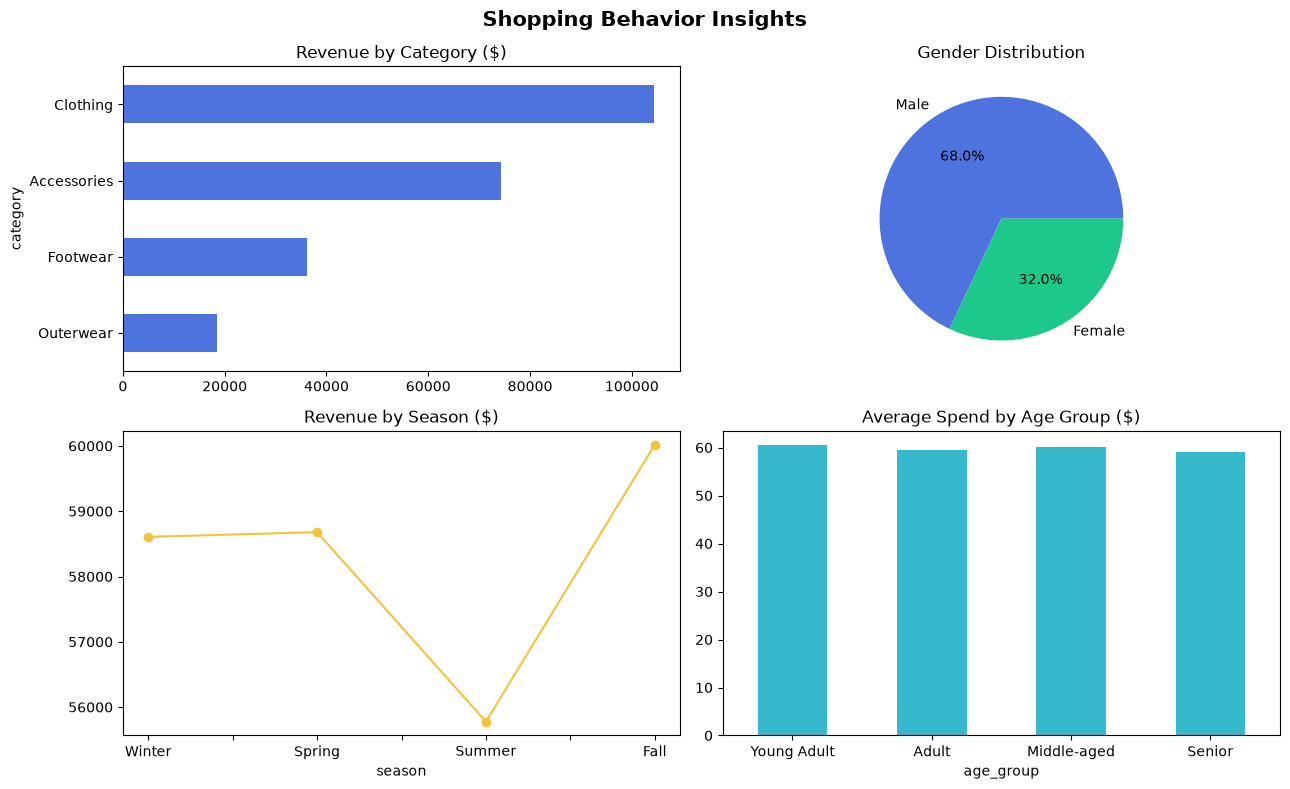

Total revenue: $233,081.00 | Customers: 3,900 | Avg spend: $59.76 | Avg rating: 3.75


In [19]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle('Shopping Behavior Insights', fontsize=15, fontweight='bold')

df.groupby('category')['purchase_amount'].sum().sort_values().plot.barh(ax=ax[0, 0], color='#4e73df')
ax[0, 0].set_title('Revenue by Category ($)')

df['gender'].value_counts().plot.pie(ax=ax[0, 1], autopct='%1.1f%%', colors=['#4e73df', '#1cc88a'])
ax[0, 1].set_title('Gender Distribution'); ax[0, 1].set_ylabel('')

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
season = df.groupby('season')['purchase_amount'].sum().reindex(season_order)
season.plot(ax=ax[1, 0], marker='o', color='#f6c23e')
ax[1, 0].set_title('Revenue by Season ($)')

df.groupby('age_group')['purchase_amount'].mean().reindex(labels).plot.bar(ax=ax[1, 1], color='#36b9cc', rot=0)
ax[1, 1].set_title('Average Spend by Age Group ($)')

plt.tight_layout()
plt.savefig('dashboard.png', dpi=150)
plt.show()

print(f"Total revenue: ${df['purchase_amount'].sum():,.2f} | "
      f"Customers: {df['customer_id'].nunique():,} | "
      f"Avg spend: ${df['purchase_amount'].mean():.2f} | "
      f"Avg rating: {df['review_rating'].mean():.2f}")